In [1]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# Load

df = pd.read_csv("data/weather.csv", parse_dates = ["time"], usecols = ["time", "precipitation"])
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2026-01-01", "2026-08-01", inclusive="left")]

df.head()

,time,precipitation
227928,2026-01-01 00:00:00-07:00,0.0
227929,2026-01-01 01:00:00-07:00,0.0
227930,2026-01-01 02:00:00-07:00,0.0
227931,2026-01-01 03:00:00-07:00,0.0
227932,2026-01-01 04:00:00-07:00,0.0


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any())

2026-01-01 00:00:00-07:00 to 2026-07-31 23:00:00-06:00 

Shape: (5087, 2) 

Dtypes:
time             datetime64[us, America/Edmonton]
precipitation                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False


In [4]:
df[["precipitation"]].describe().T

,count,mean,std,min,25%,50%,75%,max
precipitation,5087.0,0.069923,0.297736,0.0,0.0,0.0,0.0,5.7


In [5]:
# Additional Inspect

df.loc[df["precipitation"].gt(0), ["precipitation"]].describe().T

,count,mean,std,min,25%,50%,75%,max
precipitation,812.0,0.438054,0.628067,0.1,0.1,0.2,0.5,5.7


In [6]:
# Clean
# No clean required after inspection.

In [7]:
# Transform


precipitation_df = (df.loc[df["time"].ge("2026-03-26")] # history required for April 1 rolling value
                      .assign(date = lambda x: x["time"].dt.date)
                      .groupby(["date"], as_index = False).agg(daily_precipitation = ("precipitation", "sum"))
                      .copy()
)

output_df = (precipitation_df.assign(rolling_7d_precipitation = lambda x: x["daily_precipitation"].rolling(7).sum())
                             .dropna(subset=["rolling_7d_precipitation"])
)


output_df

,date,daily_precipitation,rolling_7d_precipitation
6,2026-04-01,0.2,10.9
7,2026-04-02,10.7,19.4
8,2026-04-03,0.0,19.4
9,2026-04-04,0.0,18.9
10,2026-04-05,4.6,21.3
...,...,...,...
123,2026-07-27,0.0,0.8
124,2026-07-28,0.0,0.5
125,2026-07-29,0.0,0.5
126,2026-07-30,0.0,0.0


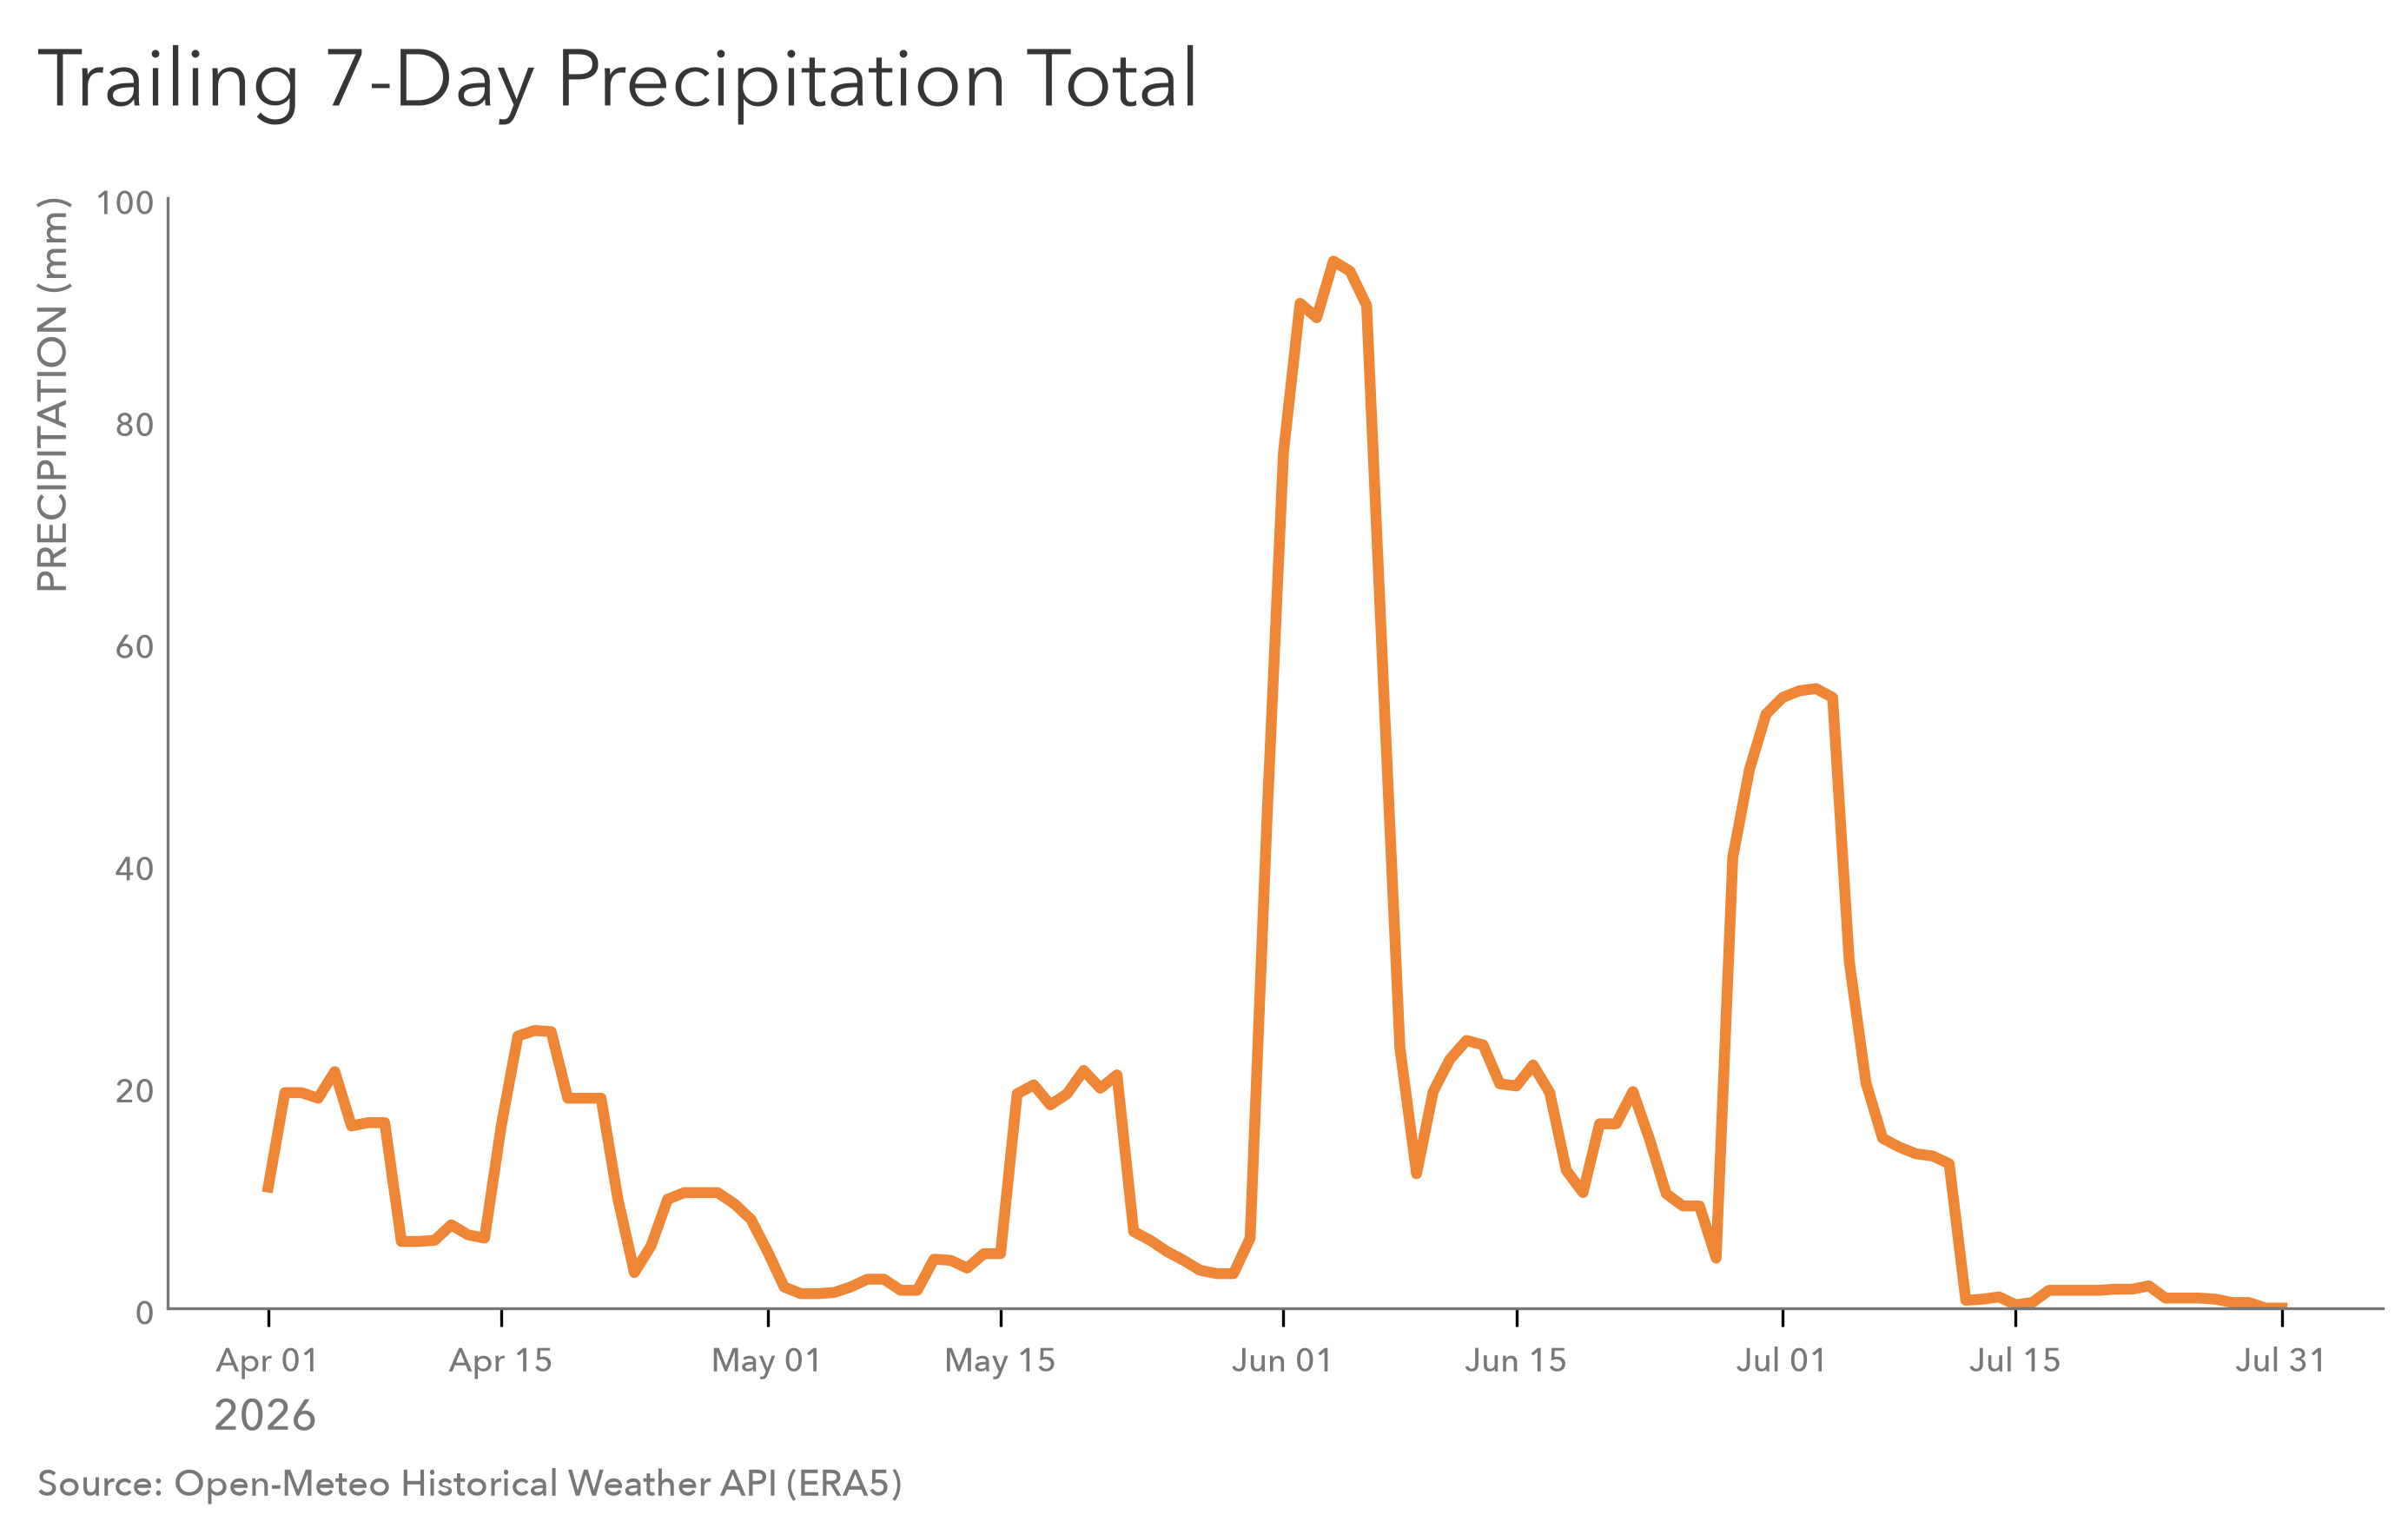

In [8]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (10, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.95,
    top = 0.85,
    bottom = 0.14
)

STRUCTURE = "#777777"
ORANGE = "#EF8636"
TITLE = "#363636"

# Plot

line, = ax.plot(output_df["date"], output_df["rolling_7d_precipitation"], linewidth = 3, color = ORANGE)

# Scale & Axes

ax.set_ylim(0, 100)

ax.set_ylabel("PRECIPITATION (mm)", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)

fig.text(0.1375, 0.09, "2026", ha = "center", va = "top", fontsize = 12, fontweight = 500, color = STRUCTURE)

# Ticks

ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# add Jul 31 tick and remove Aug 01 tick
ax.set_xticks([
    *[tick for tick in ax.get_xticks() if tick <= mdates.date2num(pd.Timestamp("2026-07-31"))],
    mdates.date2num(pd.Timestamp("2026-07-31"))
])

ax.tick_params(axis = "x", labelsize = 9, length = 5, labelcolor = STRUCTURE)

ax.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right"]].set_visible(False)
ax.spines[["bottom", "left"]].set_color(STRUCTURE)
ax.spines[["bottom", "left"]].set_linewidth(0.8)

# Composition

fig.suptitle("Trailing 7-Day Precipitation Total", x = 0.05, y = 0.96, ha = "left", va = "top", fontweight = 400, fontsize = 22, color = TITLE)

fig.text(0.05, 0.02, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 10, color = STRUCTURE)

# Output

#fig.savefig("outputs/trailing-7-day-precipitation-total-spring-summer-2026.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()